In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/manav0negi/student-performance-mock-dataindian-edition/Student_Analysis.csv


In [2]:
import matplotlib.pyplot as plt

df = pd.read_csv('/kaggle/input/datasets/manav0negi/student-performance-mock-dataindian-edition/Student_Analysis.csv', keep_default_na=False, na_values=[""])

print(df.shape)
print(df.columns.tolist())
df.head()

(3000, 11)
['University-ID', 'Name', 'Gender', 'Course', 'Branch', 'Age', 'Marks(%)', 'Pass/Fail', 'Grade', 'Attendance(%)', 'Hostel/Day Scholar']


,University-ID,Name,Gender,Course,Branch,Age,Marks(%),Pass/Fail,Grade,Attendance(%),Hostel/Day Scholar
0,2027-0001,Anita Chundawat,Female,BCom,N/A,20,65,Pass,C,69,Day Scholar
1,2027-0002,Vijay Mankotia,Male,MBA,N/A,23,73,Pass,B,57,Day Scholar
2,2027-0003,Jyoti Aswal,Female,BBA,N/A,20,79,Pass,B,78,Day Scholar
3,2027-0004,Chandan Panwar,Male,MCA,N/A,23,82,Pass,A,97,Hostel
4,2027-0005,Shashi Hegde,Male,B-Tech,EE,19,77,Pass,B,78,Day Scholar


Total students: 3000
Gender
Female    1500
Male      1500
Name: count, dtype: int64
Course
B-Tech    1167
BBA        474
BCom       450
BCA        449
BA         235
MBA        128
MCA         97
Name: count, dtype: int64
Hostel/Day Scholar
Day Scholar    2283
Hostel          717
Name: count, dtype: int64


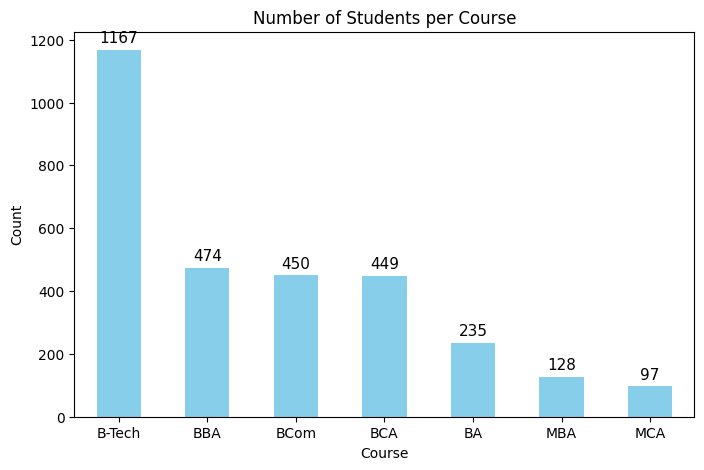

In [3]:
print("Total students:", len(df))

# By gender
print(df['Gender'].value_counts())

# By course
print(df['Course'].value_counts())

# By hostel/day scholar
print(df['Hostel/Day Scholar'].value_counts())

# Bar chart of students per course (with numbers on top)
ax = df['Course'].value_counts().plot(kind='bar', figsize=(8,5), color='skyblue')

for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

plt.title('Number of Students per Course')
plt.xlabel('Course')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

Total B-Tech students: 1167
Branch
CSE    685
EE     170
ME     165
CE     147
Name: count, dtype: int64


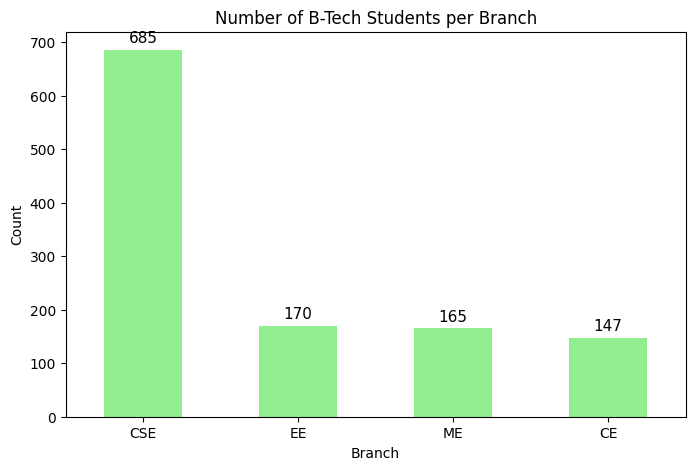

In [4]:
# Filter only B-Tech students
btech = df[df['Course'] == 'B-Tech']

print("Total B-Tech students:", len(btech))
print(btech['Branch'].value_counts())

# Bar chart with numbers on top
ax = btech['Branch'].value_counts().plot(kind='bar', figsize=(8,5), color='lightgreen')

for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

plt.title('Number of B-Tech Students per Branch')
plt.xlabel('Branch')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

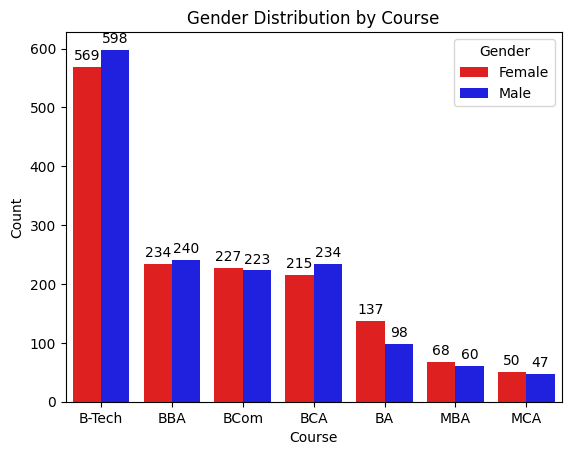

In [5]:
colors = {'Male': 'blue', 'Female': 'red'}

ax = sns.countplot(data=df, x='Course', hue='Gender',
                   order=df['Course'].value_counts().index,
                   palette=colors)

for container in ax.containers:
    ax.bar_label(container, fontsize=10, padding=3)

plt.title('Gender Distribution by Course')
plt.xlabel('Course')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()

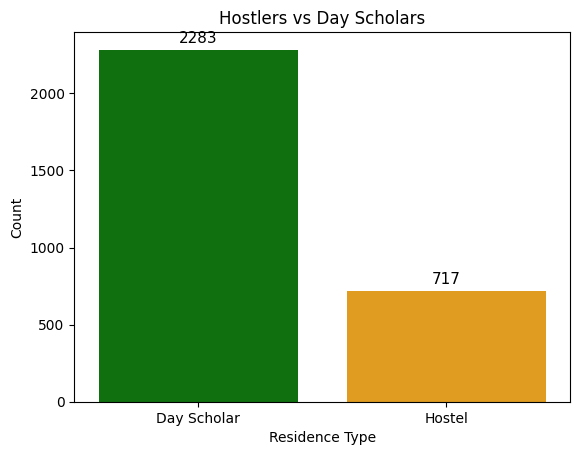

In [6]:
ax = sns.countplot(data=df, x='Hostel/Day Scholar',
                   hue='Hostel/Day Scholar',
                   order=df['Hostel/Day Scholar'].value_counts().index,
                   palette={'Hostel': 'orange', 'Day Scholar': 'green'},
                   legend=False)

for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

plt.title('Hostlers vs Day Scholars')
plt.xlabel('Residence Type')
plt.ylabel('Count')
plt.show()

Hostel/Day Scholar  Day Scholar  Hostel
Course                                 
B-Tech                      888     279
BA                          174      61
BBA                         368     106
BCA                         346     103
BCom                        342     108
MBA                          92      36
MCA                          73      24


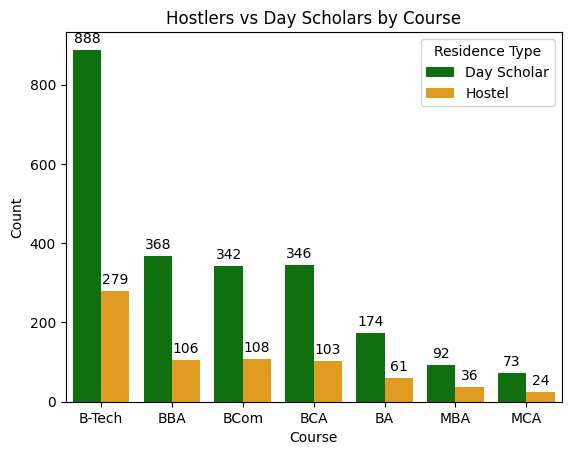

In [7]:
# Table of counts
print(pd.crosstab(df['Course'], df['Hostel/Day Scholar']))

# Grouped bar chart with numbers on top
colors = {'Hostel': 'orange', 'Day Scholar': 'green'}

ax = sns.countplot(data=df, x='Course', hue='Hostel/Day Scholar',
                   order=df['Course'].value_counts().index,
                   palette=colors)

for container in ax.containers:
    ax.bar_label(container, fontsize=10, padding=3)

plt.title('Hostlers vs Day Scholars by Course')
plt.xlabel('Course')
plt.ylabel('Count')
plt.legend(title='Residence Type')
plt.show()

Gender              Female  Male
Hostel/Day Scholar              
Day Scholar           1150  1133
Hostel                 350   367


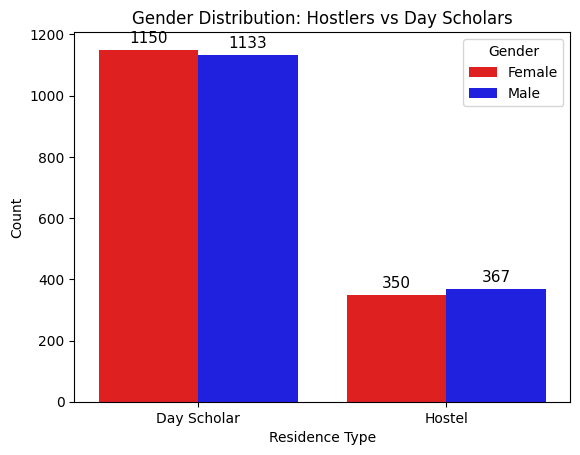

In [8]:
# Table of counts
print(pd.crosstab(df['Hostel/Day Scholar'], df['Gender']))

# Grouped bar chart with numbers on top
colors = {'Male': 'blue', 'Female': 'red'}

ax = sns.countplot(data=df, x='Hostel/Day Scholar', hue='Gender',
                   order=df['Hostel/Day Scholar'].value_counts().index,
                   palette=colors)

for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

plt.title('Gender Distribution: Hostlers vs Day Scholars')
plt.xlabel('Residence Type')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()

Age
19    938
20    902
21    935
23    106
24    119
Name: count, dtype: int64


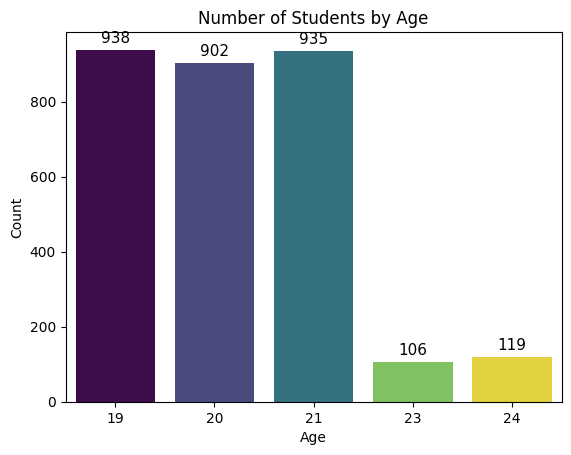

In [9]:
# Counts per age
print(df['Age'].value_counts().sort_index())

# Bar chart with numbers on top
ax = sns.countplot(data=df, x='Age', hue='Age', palette='viridis', legend=False)

for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

plt.title('Number of Students by Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

Gender  Female  Male
Age                 
19         461   477
20         467   435
21         454   481
23          59    47
24          59    60


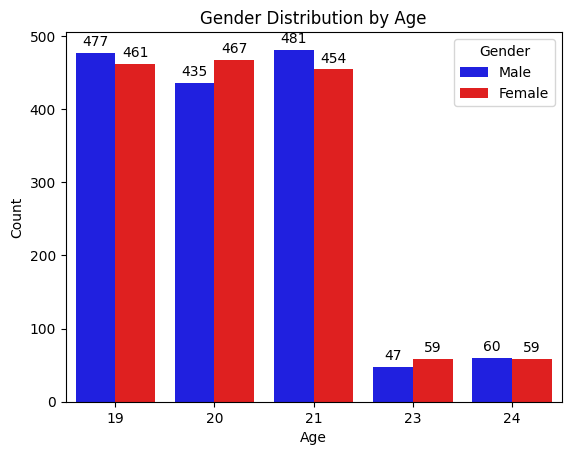

In [10]:
# Table of counts
print(pd.crosstab(df['Age'], df['Gender']))

# Grouped bar chart with numbers on top
colors = {'Male': 'blue', 'Female': 'red'}

ax = sns.countplot(data=df, x='Age', hue='Gender', palette=colors)

for container in ax.containers:
    ax.bar_label(container, fontsize=10, padding=3)

plt.title('Gender Distribution by Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()

Pass/Fail
Pass    2938
Fail      62
Name: count, dtype: int64
Pass/Fail
Pass    97.9
Fail     2.1
Name: proportion, dtype: float64


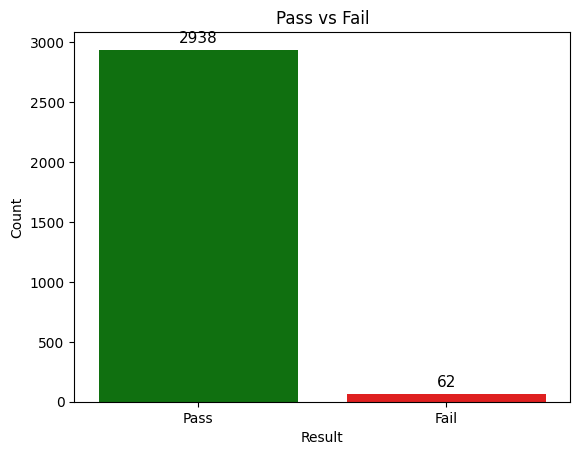

In [11]:
# Counts and percentages
print(df['Pass/Fail'].value_counts())
print((df['Pass/Fail'].value_counts(normalize=True) * 100).round(1))

# Bar chart with numbers on top
ax = sns.countplot(data=df, x='Pass/Fail', hue='Pass/Fail',
                   order=df['Pass/Fail'].value_counts().index,
                   palette={'Pass': 'green', 'Fail': 'red'},
                   legend=False)

for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

plt.title('Pass vs Fail')
plt.xlabel('Result')
plt.ylabel('Count')
plt.show()

Pass/Fail  Fail  Pass
Course               
B-Tech       26  1141
BA            7   228
BBA           9   465
BCA           7   442
BCom          8   442
MBA           0   128
MCA           5    92


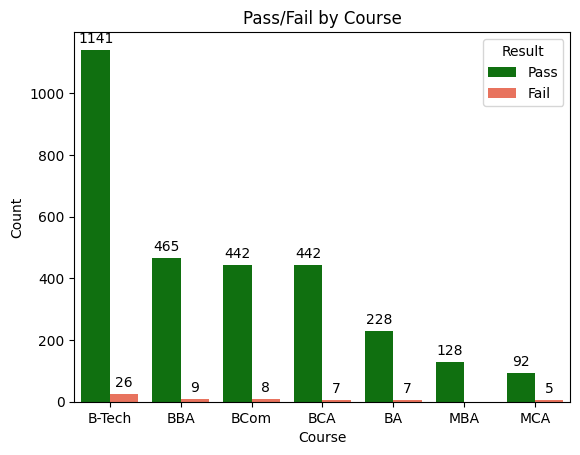

In [12]:
# Table of counts
print(pd.crosstab(df['Course'], df['Pass/Fail']))

# Grouped bar chart with numbers on top
ax = sns.countplot(data=df, x='Course', hue='Pass/Fail',
                   order=df['Course'].value_counts().index,
                   palette={'Pass': 'green', 'Fail': 'tomato'})

for container in ax.containers:
    ax.bar_label(container, fontsize=10, padding=3)

plt.title('Pass/Fail by Course')
plt.xlabel('Course')
plt.ylabel('Count')
plt.legend(title='Result')
plt.show()

Pass/Fail  Fail  Pass
Gender               
Female       30  1470
Male         32  1468


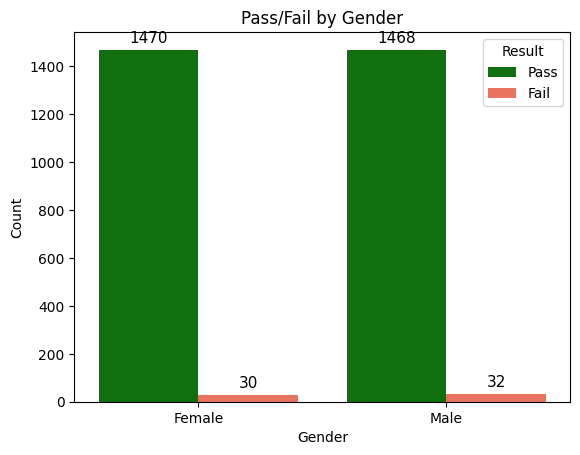

In [13]:
# Table of counts
print(pd.crosstab(df['Gender'], df['Pass/Fail']))

# Grouped bar chart with numbers on top
ax = sns.countplot(data=df, x='Gender', hue='Pass/Fail',
                   palette={'Pass': 'green', 'Fail': 'tomato'})

for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

plt.title('Pass/Fail by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Result')
plt.show()

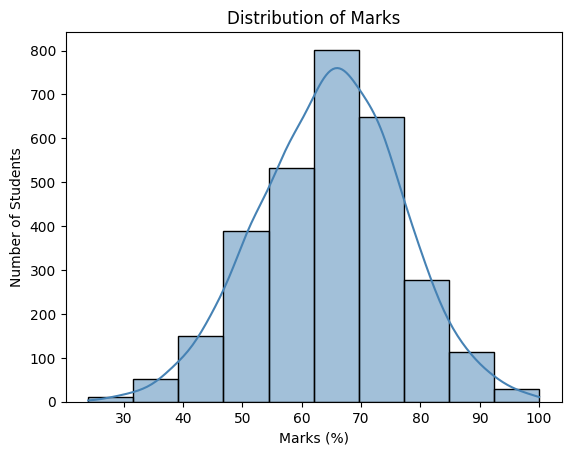

In [14]:
sns.histplot(data=df, x='Marks(%)', bins=10, kde=True, color='steelblue')

plt.title('Distribution of Marks')
plt.xlabel('Marks (%)')
plt.ylabel('Number of Students')
plt.show()

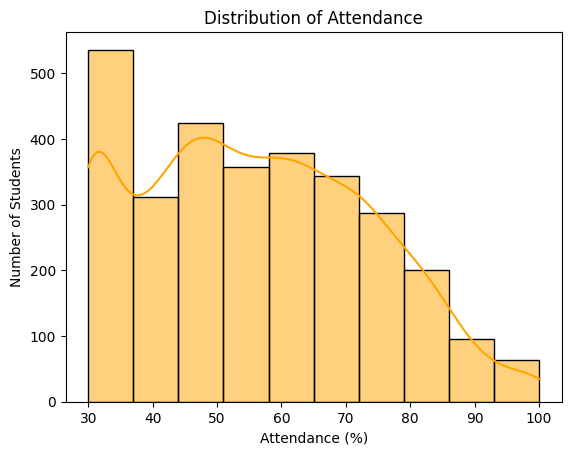

In [15]:
sns.histplot(data=df, x='Attendance(%)', bins=10, kde=True, color='orange')

plt.title('Distribution of Attendance')
plt.xlabel('Attendance (%)')
plt.ylabel('Number of Students')
plt.show()

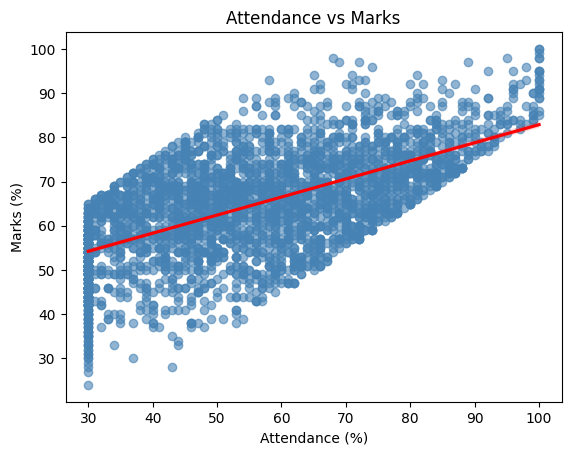

In [16]:
sns.regplot(data=df, x='Attendance(%)', y='Marks(%)',
            scatter_kws={'color': 'steelblue', 'alpha': 0.6},
            line_kws={'color': 'red'})

plt.title('Attendance vs Marks')
plt.xlabel('Attendance (%)')
plt.ylabel('Marks (%)')
plt.show()

In [17]:
# Top 10 students by marks
top10 = df.sort_values(by='Marks(%)', ascending=False).head(10)

# Table (index starts from 1)
top10_display = top10[['University-ID', 'Name', 'Course', 'Gender', 'Marks(%)', 'Grade', 'Attendance(%)']].reset_index(drop=True)
top10_display.index = top10_display.index + 1
print(top10_display)

   University-ID              Name  Course  Gender  Marks(%) Grade  \
1      2027-2097       Durga Bhati  B-Tech  Female       100    A+   
2      2027-0725     Bandana Gogoi  B-Tech  Female       100    A+   
3      2027-0842    Jyoti Naithani    BCom  Female        99    A+   
4      2027-0511  Dechen Denzongpa    BCom  Female        98    A+   
5      2027-2118      Nyima Bhutia    BCom  Female        98    A+   
6      2027-2253          Junu Das  B-Tech  Female        98    A+   
7      2027-1666   Nirmala Chandel    BCom  Female        98    A+   
8      2027-0520    Parvati Jangid     BBA  Female        97    A+   
9      2027-2313         Anil Sood  B-Tech    Male        97    A+   
10     2027-1503    Malathi Palani     BCA  Female        97    A+   

    Attendance(%)  
1             100  
2             100  
3             100  
4             100  
5              68  
6              95  
7             100  
8              72  
9              69  
10             89  


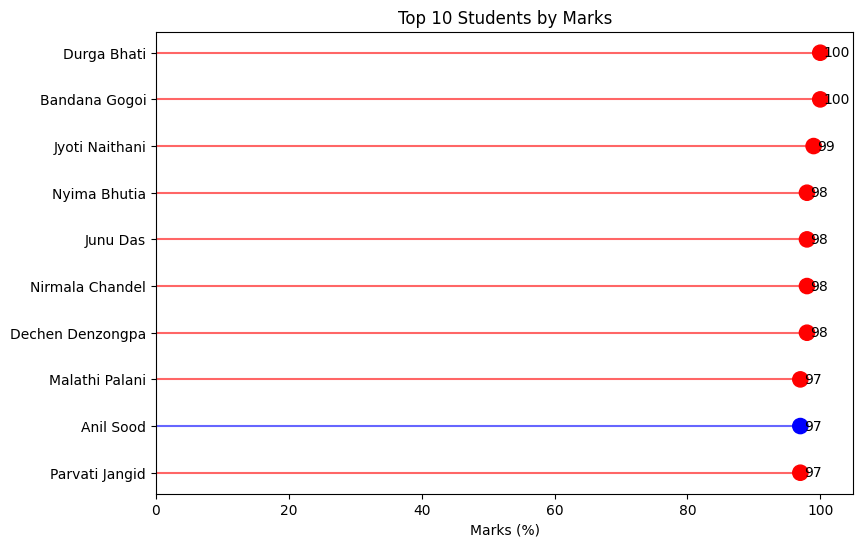

In [18]:
top10_sorted = top10.sort_values('Marks(%)')
colors = top10_sorted['Gender'].map({'Male': 'blue', 'Female': 'red'})

plt.figure(figsize=(9, 6))
plt.hlines(y=top10_sorted['Name'], xmin=0, xmax=top10_sorted['Marks(%)'], color=colors, alpha=0.6)
plt.scatter(top10_sorted['Marks(%)'], top10_sorted['Name'], color=colors, s=120, zorder=3)

# Marks written next to each dot
for marks, name in zip(top10_sorted['Marks(%)'], top10_sorted['Name']):
    plt.text(marks + 0.5, name, f'{marks}', va='center', fontsize=10)

plt.title('Top 10 Students by Marks')
plt.xlabel('Marks (%)')
plt.xlim(0, 105)
plt.show()

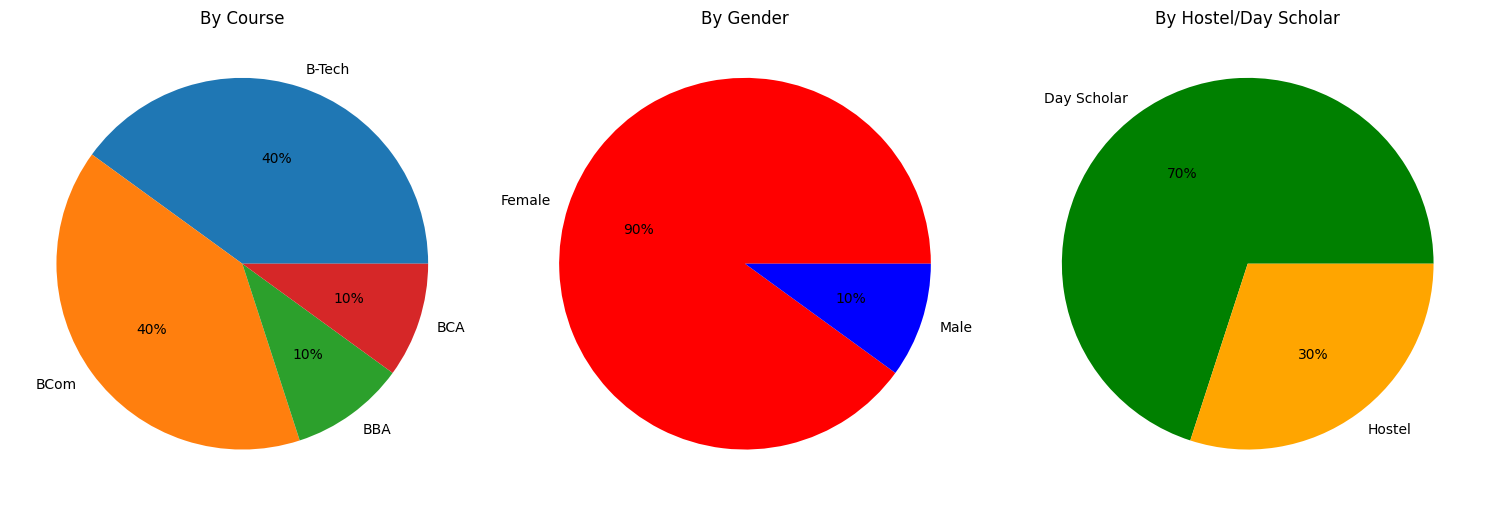

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

top10['Course'].value_counts().plot(kind='pie', autopct='%1.0f%%', ax=axes[0])
axes[0].set_title('By Course')
axes[0].set_ylabel('')

top10['Gender'].value_counts().plot(kind='pie', autopct='%1.0f%%', ax=axes[1],
                                    colors=['blue' if g == 'Male' else 'red' for g in top10['Gender'].value_counts().index])
axes[1].set_title('By Gender')
axes[1].set_ylabel('')

top10['Hostel/Day Scholar'].value_counts().plot(kind='pie', autopct='%1.0f%%', ax=axes[2],
                                                colors=['green' if h == 'Day Scholar' else 'orange' for h in top10['Hostel/Day Scholar'].value_counts().index])
axes[2].set_title('By Hostel/Day Scholar')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

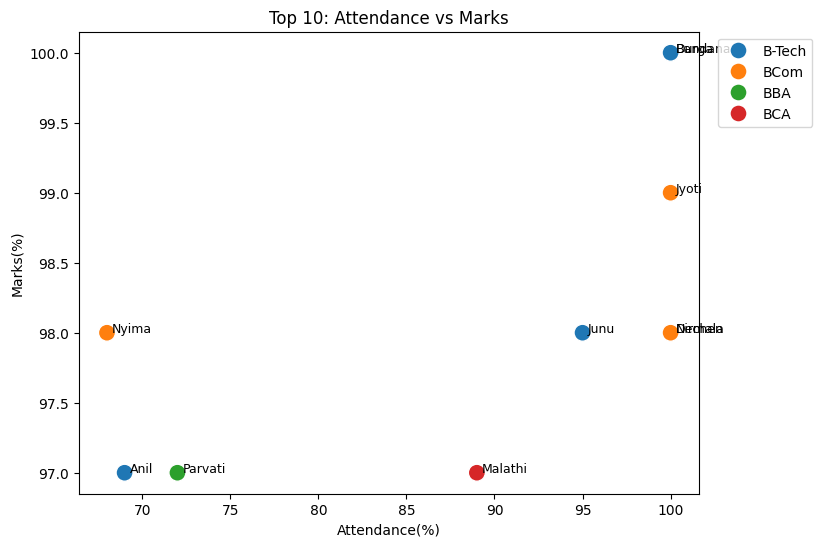

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=top10, x='Attendance(%)', y='Marks(%)', hue='Course', s=150)

for _, row in top10.iterrows():
    plt.text(row['Attendance(%)'] + 0.3, row['Marks(%)'], row['Name'].split()[0], fontsize=9)

plt.title('Top 10: Attendance vs Marks')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

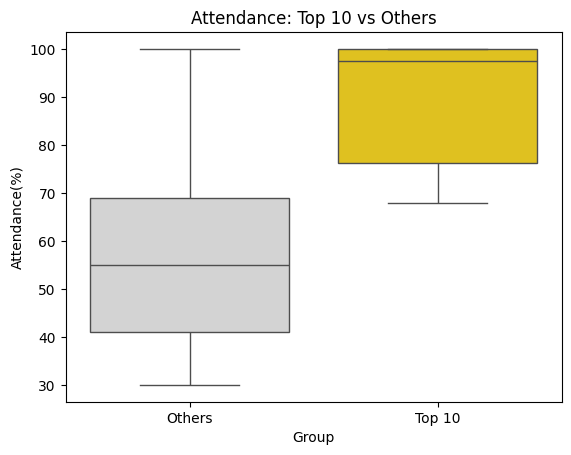

In [21]:
df['Group'] = ['Top 10' if i in top10.index else 'Others' for i in df.index]

sns.boxplot(data=df, x='Group', y='Attendance(%)', hue='Group',
            palette={'Top 10': 'gold', 'Others': 'lightgray'}, legend=False)
plt.title('Attendance: Top 10 vs Others')
plt.show()